# Questions

How does Fitbit daily steps and total active minutes correlate?

How does daily steps differ between on the weekdays such as Mon - Fri to weekends (Sat - Sun)?

How does NHANES measure the movement by various data such as age and more?

We shorten our questions to activity patterns correlation but still working on it.

In [6]:
import polars as pl

fitbit_raw_data = pl.read_csv(
    "data/Fitbit Fitness Tracker Data/dailyActivity_merged.csv",
    infer_schema_length=None,
)

fitbit_raw_data.head()

Id,ActivityDate,TotalSteps,TotalDistance,TrackerDistance,LoggedActivitiesDistance,VeryActiveDistance,ModeratelyActiveDistance,LightActiveDistance,SedentaryActiveDistance,VeryActiveMinutes,FairlyActiveMinutes,LightlyActiveMinutes,SedentaryMinutes,Calories
i64,str,i64,f64,f64,f64,f64,f64,f64,f64,i64,i64,i64,i64,i64
1503960366,"""4/12/2016""",13162,8.5,8.5,0.0,1.88,0.55,6.06,0.0,25,13,328,728,1985
1503960366,"""4/13/2016""",10735,6.97,6.97,0.0,1.57,0.69,4.71,0.0,21,19,217,776,1797
1503960366,"""4/14/2016""",10460,6.74,6.74,0.0,2.44,0.4,3.91,0.0,30,11,181,1218,1776
1503960366,"""4/15/2016""",9762,6.28,6.28,0.0,2.14,1.26,2.83,0.0,29,34,209,726,1745
1503960366,"""4/16/2016""",12669,8.16,8.16,0.0,2.71,0.41,5.04,0.0,36,10,221,773,1863


In [7]:
fitbit_raw_data.shape

(940, 15)

In [13]:
fitbit_raw_data.schema

Schema([('Id', Int64),
        ('ActivityDate', String),
        ('TotalSteps', Int64),
        ('TotalDistance', Float64),
        ('TrackerDistance', Float64),
        ('LoggedActivitiesDistance', Float64),
        ('VeryActiveDistance', Float64),
        ('ModeratelyActiveDistance', Float64),
        ('LightActiveDistance', Float64),
        ('SedentaryActiveDistance', Float64),
        ('VeryActiveMinutes', Int64),
        ('FairlyActiveMinutes', Int64),
        ('LightlyActiveMinutes', Int64),
        ('SedentaryMinutes', Int64),
        ('Calories', Int64)])

In [10]:
fitbit_raw_data.null_count()

Id,ActivityDate,TotalSteps,TotalDistance,TrackerDistance,LoggedActivitiesDistance,VeryActiveDistance,ModeratelyActiveDistance,LightActiveDistance,SedentaryActiveDistance,VeryActiveMinutes,FairlyActiveMinutes,LightlyActiveMinutes,SedentaryMinutes,Calories
u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [11]:
fitbit_raw_data.describe()

statistic,Id,ActivityDate,TotalSteps,TotalDistance,TrackerDistance,LoggedActivitiesDistance,VeryActiveDistance,ModeratelyActiveDistance,LightActiveDistance,SedentaryActiveDistance,VeryActiveMinutes,FairlyActiveMinutes,LightlyActiveMinutes,SedentaryMinutes,Calories
str,f64,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""count""",940.0,"""940""",940.0,940.0,940.0,940.0,940.0,940.0,940.0,940.0,940.0,940.0,940.0,940.0,940.0
"""null_count""",0.0,"""0""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""mean""",4.8554e9,null,7637.910638,5.489702,5.475351,0.108171,1.502681,0.567543,3.340819,0.001606,21.164894,13.564894,192.812766,991.210638,2303.609574
"""std""",2.4248e9,null,5087.150742,3.924606,3.907276,0.619897,2.658941,0.88358,2.040655,0.007346,32.844803,19.987404,109.1747,301.267437,718.166862
"""min""",1.5040e9,"""4/12/2016""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""25%""",2.3201e9,null,3790.0,2.62,2.62,0.0,0.0,0.0,1.95,0.0,0.0,0.0,127.0,730.0,1829.0
"""50%""",4.4451e9,null,7412.0,5.25,5.25,0.0,0.21,0.24,3.37,0.0,4.0,6.0,199.0,1058.0,2135.0
"""75%""",6.9622e9,null,10725.0,7.71,7.71,0.0,2.04,0.8,4.78,0.0,32.0,19.0,264.0,1229.0,2793.0
"""max""",8.8777e9,"""5/9/2016""",36019.0,28.030001,28.030001,4.942142,21.92,6.48,10.71,0.11,210.0,143.0,518.0,1440.0,4900.0


# Fitbit datasets profiles

# 940 rows & 15 cols. each row represents one person activity per day (one)

# AcivityDate is convert from text to date (weekdays + weekends). Other random variables are ints such as steps and activity minutes. Additional distance is in decimial value

# The minimiuim steps are 0 and also for calories without no null values shown.

# avg step is 7,638 with a deviation of 5,087 acrross days.

In [14]:
zero_days = fitbit_raw_data.filter(pl.col("TotalSteps") == 0)

zero_days.shape

(77, 15)

In [17]:
zero_c_days = fitbit_raw_data.filter(pl.col("Calories") == 0)

zero_c_days.shape

(4, 15)

In [18]:
zero_c_days.select(
    "Id",
    "ActivityDate",
    "TotalSteps",
    "VeryActiveMinutes",
    "LightlyActiveMinutes",
    "SedentaryMinutes",
    "Calories",
)

Id,ActivityDate,TotalSteps,VeryActiveMinutes,LightlyActiveMinutes,SedentaryMinutes,Calories
i64,str,i64,i64,i64,i64,i64
1503960366,"""5/12/2016""",0,0,0,1440,0
6290855005,"""5/10/2016""",0,0,0,1440,0
8253242879,"""4/30/2016""",0,0,0,1440,0
8583815059,"""5/12/2016""",0,0,0,1440,0


# zero value anomalies

# 77 zero step days and 4 with zero calories, and with 1440 sedentary minutes

# We should exclude the raw values because may indicate not complete accurate data such as activity to inacivity to acitivity.



In [19]:
d_cond = fitbit_raw_data.is_duplicated()

d_rows = fitbit_raw_data.filter(d_cond)

d_rows.shape

(0, 15)

# Also no duplicates rows.

In [ ]:
negative_condition = (pl.col("TotalSteps") < 0) | (pl.col("VeryActiveMinutes") < 0) | (pl.col("FairlyActiveMinutes") < 0) | (pl.col("LightlyActiveMinutes") < 0) | (pl.col("SedentaryMinutes") < 0) | (pl.col("Calories") < 0)

negative_rows = fitbit_raw_data.filter(negative_condition)

negative_rows.shape

Schema([('Id', Int64),
        ('ActivityDate', Date),
        ('TotalSteps', Int64),
        ('TotalDistance', Float64),
        ('TrackerDistance', Float64),
        ('LoggedActivitiesDistance', Float64),
        ('VeryActiveDistance', Float64),
        ('ModeratelyActiveDistance', Float64),
        ('LightActiveDistance', Float64),
        ('SedentaryActiveDistance', Float64),
        ('VeryActiveMinutes', Int64),
        ('FairlyActiveMinutes', Int64),
        ('LightlyActiveMinutes', Int64),
        ('SedentaryMinutes', Int64),
        ('Calories', Int64)])

In [26]:
fitbit_data = fitbit_raw_data.with_columns(pl.col("ActivityDate").str.strptime(pl.Date, format="%m/%d/%Y"))

fitbit_data.schema

Schema([('Id', Int64),
        ('ActivityDate', Date),
        ('TotalSteps', Int64),
        ('TotalDistance', Float64),
        ('TrackerDistance', Float64),
        ('LoggedActivitiesDistance', Float64),
        ('VeryActiveDistance', Float64),
        ('ModeratelyActiveDistance', Float64),
        ('LightActiveDistance', Float64),
        ('SedentaryActiveDistance', Float64),
        ('VeryActiveMinutes', Int64),
        ('FairlyActiveMinutes', Int64),
        ('LightlyActiveMinutes', Int64),
        ('SedentaryMinutes', Int64),
        ('Calories', Int64)])

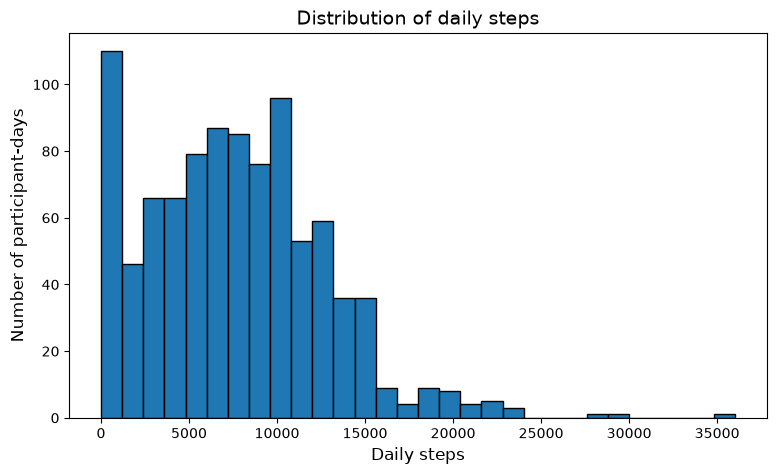

In [27]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))
plt.hist(fitbit_data["TotalSteps"].to_numpy(), bins=30, edgecolor="black")
plt.xlabel("Daily steps", fontsize=12)
plt.ylabel("Number of participant-days", fontsize=12)
plt.title("Distribution of daily steps", fontsize=14)
plt.show()

# Daily steps distribution

# right skewed data on 15k steps and a tail on 36k steps. Mean is around 7638 and median to be 7412. middle 50% fall between around 3790 to 10725. Additional details are 77 zero step days as other very low days.

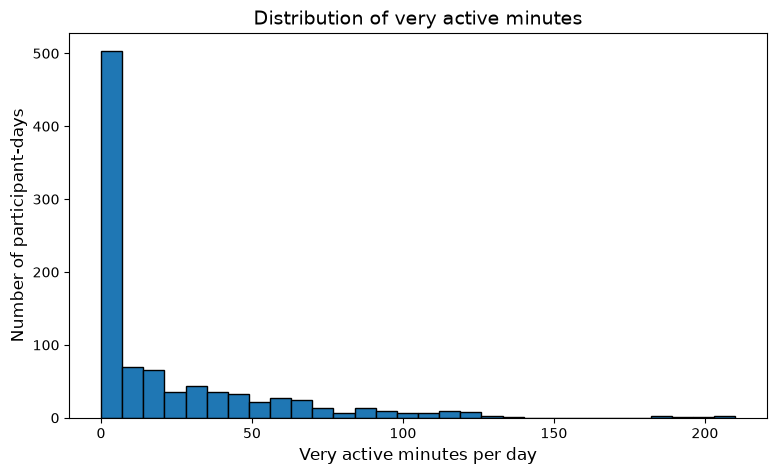

In [28]:
plt.figure(figsize=(9, 5))
plt.hist(fitbit_data["VeryActiveMinutes"].to_numpy(), bins=30, edgecolor="black")
plt.xlabel("Very active minutes per day", fontsize=12)
plt.ylabel("Number of participant-days", fontsize=12)
plt.title("Distribution of very active minutes", fontsize=14)
plt.show()

# Very active minutes distri

# right skewed toward trend data with and upper tail. While the bin includes the both zero value and small one too. Median is 4 minutes, with the means at 21.16 and middle 50% between 0 to 32 mins, with range being 0 to 210. The means is above the median too

In [29]:
fitbit_data.select("VeryActiveMinutes").describe()


statistic,VeryActiveMinutes
str,f64
"""count""",940.0
"""null_count""",0.0
"""mean""",21.164894
"""std""",32.844803
"""min""",0.0
"""25%""",0.0
"""50%""",4.0
"""75%""",32.0
"""max""",210.0


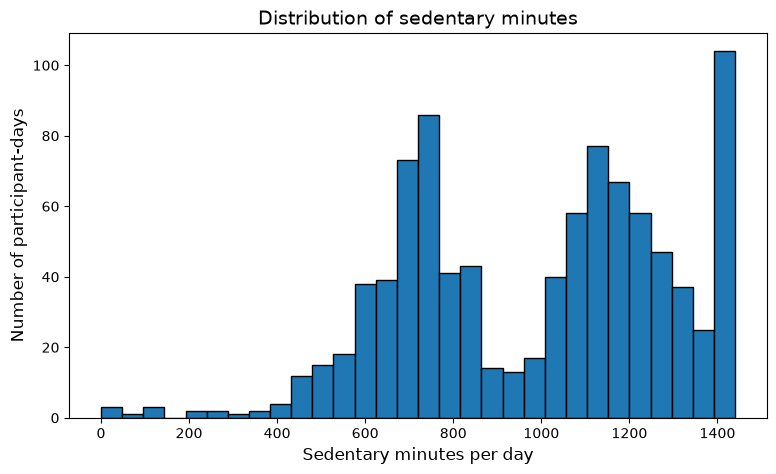

In [30]:
plt.figure(figsize=(9, 5))
plt.hist(fitbit_data["SedentaryMinutes"].to_numpy(), bins=30, edgecolor="black")
plt.xlabel("Sedentary minutes per day", fontsize=12)
plt.ylabel("Number of participant-days", fontsize=12)
plt.title("Distribution of sedentary minutes", fontsize=14)
plt.show()

In [31]:
fitbit_data.select("SedentaryMinutes").describe()

statistic,SedentaryMinutes
str,f64
"""count""",940.0
"""null_count""",0.0
"""mean""",991.210638
"""std""",301.267437
"""min""",0.0
"""25%""",730.0
"""50%""",1058.0
"""75%""",1229.0
"""max""",1440.0


# Sedentary min distri

# Mean is 991 mins, median is 1058, and middle 50% is between 730 to 1229, with a big range of 0 to 1440minss

# the tail toward the low vals.

In [34]:
full_day_condition = pl.col("SedentaryMinutes") == 1440

full_day_rows = fitbit_data.filter(full_day_condition)

full_day_rows.shape

(79, 15)

In [33]:
full_day_rows.select("Id", "ActivityDate", "TotalSteps", "Calories")

Id,ActivityDate,TotalSteps,Calories
i64,date,i64,i64
1503960366,2016-05-12,0,0
1844505072,2016-04-24,0,1347
1844505072,2016-04-25,0,1347
1844505072,2016-04-26,0,1347
1844505072,2016-05-02,0,1348
…,…,…,…
8792009665,2016-05-05,0,1688
8792009665,2016-05-06,0,1688
8792009665,2016-05-07,0,1688


# 79 days with record of 1440 sedentary mins. 72 with no steps and 7 pos steps. 

This also suggest inconsistent between our data on the sendtary time compared to the movement of xyz.

In [35]:
full_day_zero_steps = full_day_rows.filter(pl.col("TotalSteps") == 0)

full_day_zero_steps.shape

(72, 15)

In [36]:
full_day_positive_steps = full_day_rows.filter(pl.col("TotalSteps") > 0)

full_day_positive_steps.select("Id", "ActivityDate", "TotalSteps", "Calories")

Id,ActivityDate,TotalSteps,Calories
i64,date,i64,i64
4319703577,2016-04-12,7753,2115
4388161847,2016-04-12,10122,2955
8583815059,2016-04-16,5319,2693
8583815059,2016-04-17,3008,2439
8583815059,2016-05-02,8469,2894
8583815059,2016-05-03,12015,3212
8583815059,2016-05-04,3588,2516


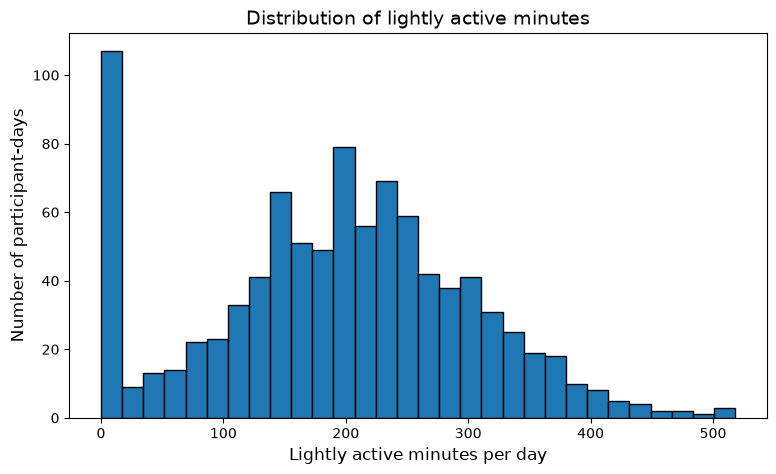

In [37]:
plt.figure(figsize=(9, 5))
plt.hist(fitbit_data["LightlyActiveMinutes"].to_numpy(), bins=30, edgecolor="black")
plt.xlabel("Lightly active minutes per day", fontsize=12)
plt.ylabel("Number of participant-days", fontsize=12)
plt.title("Distribution of lightly active minutes", fontsize=14)
plt.show()

In [38]:
fitbit_data.select("LightlyActiveMinutes").describe()

statistic,LightlyActiveMinutes
str,f64
"""count""",940.0
"""null_count""",0.0
"""mean""",192.812766
"""std""",109.1747
"""min""",0.0
"""25%""",127.0
"""50%""",199.0
"""75%""",264.0
"""max""",518.0


# lightly active minutes distri

# About 200 minutes with mean at 192.81 minute and median is about 199. The middle 50% falls between 127 and 264 minutes, with vals at 0 to 518.

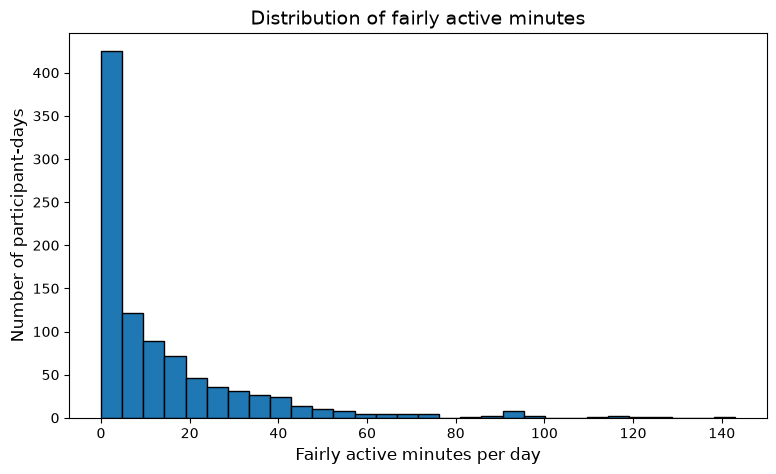

In [39]:
plt.figure(figsize=(9, 5))
plt.hist(fitbit_data["FairlyActiveMinutes"].to_numpy(), bins=30, edgecolor="black")
plt.xlabel("Fairly active minutes per day", fontsize=12)
plt.ylabel("Number of participant-days", fontsize=12)
plt.title("Distribution of fairly active minutes", fontsize=14)
plt.show()

In [40]:
fitbit_data.select("FairlyActiveMinutes").describe()

statistic,FairlyActiveMinutes
str,f64
"""count""",940.0
"""null_count""",0.0
"""mean""",13.564894
"""std""",19.987404
"""min""",0.0
"""25%""",0.0
"""50%""",6.0
"""75%""",19.0
"""max""",143.0


# Fairly active mins distri

# Right skewed with particpiant days with some near zero and even a long tail at the upper. The mean is at 13.56 and median is 6 minutes. The middle 50% falls between 0 and 19 and range of 0 to 143.

In [41]:
active_minutes = pl.col("LightlyActiveMinutes") + pl.col("FairlyActiveMinutes") + pl.col("VeryActiveMinutes")

fitbit_data = fitbit_data.with_columns(active_minutes.alias("ActiveMinutes"))

fitbit_data.select("LightlyActiveMinutes", "FairlyActiveMinutes", "VeryActiveMinutes", "ActiveMinutes").head()

LightlyActiveMinutes,FairlyActiveMinutes,VeryActiveMinutes,ActiveMinutes
i64,i64,i64,i64
328,13,25,366
217,19,21,257
181,11,30,222
209,34,29,272
221,10,36,267


# Active Minutes is is inclusion of all sum of data on participant days.

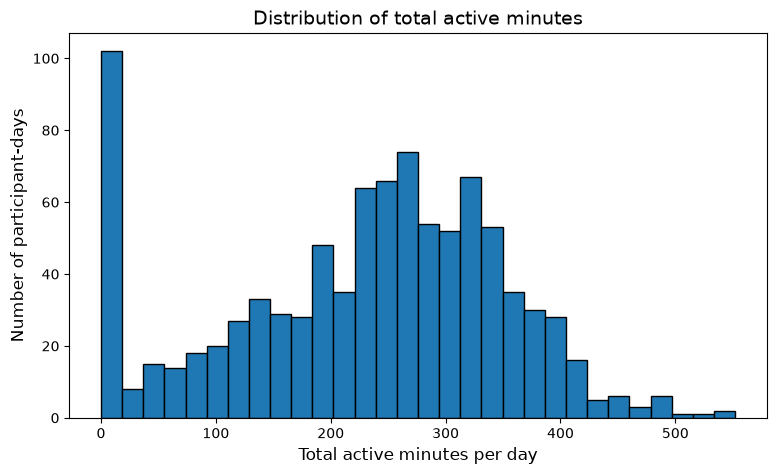

In [42]:
plt.figure(figsize=(9, 5))
plt.hist(fitbit_data["ActiveMinutes"].to_numpy(), bins=30, edgecolor="black")
plt.xlabel("Total active minutes per day", fontsize=12)
plt.ylabel("Number of participant-days", fontsize=12)
plt.title("Distribution of total active minutes", fontsize=14)
plt.show()

In [43]:
fitbit_data.select("ActiveMinutes").describe()

statistic,ActiveMinutes
str,f64
"""count""",940.0
"""null_count""",0.0
"""mean""",227.542553
"""std""",121.776307
"""min""",0.0
"""25%""",147.0
"""50%""",247.0
"""75%""",317.0
"""max""",552.0


# Total active minutes distribution

Active Minutes is the sum of equation for all type of energy from light to very hyper active for each xyz day.

The mean is 227.54 minutes and the median is 247 mins. The middle 50% falls between the 147 to 317 and a range from 0 to 552. Relating in some spike in near to bottom 0 with some higher spikes.

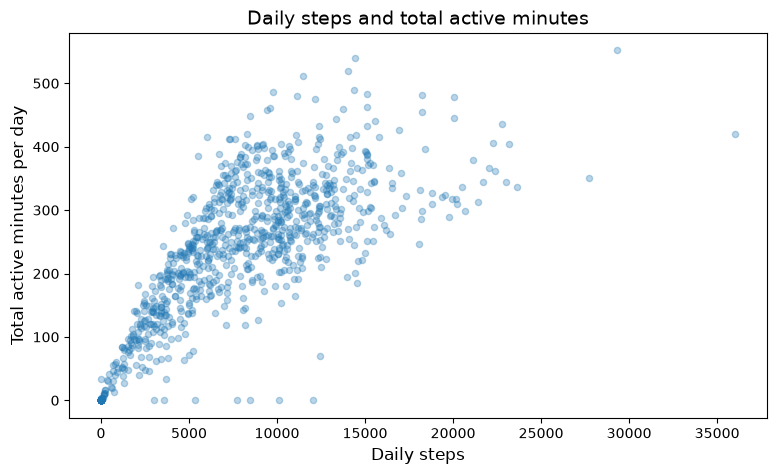

In [45]:
plt.figure(figsize=(9, 5))
plt.scatter(fitbit_data["TotalSteps"].to_numpy(), fitbit_data["ActiveMinutes"].to_numpy(), alpha=0.3, s=20)
plt.xlabel("Daily steps", fontsize=12)
plt.ylabel("Total active minutes per day", fontsize=12)
plt.title("Daily steps and total active minutes", fontsize=14)
plt.show()

# Relationship between daily steps and active minutes (total)

Higher steps always correlate with higher minute count because more will always result in more but active minutes may vary substantially at similar step count depending on speed etc. 

This relates us to deep dive into the research of postive days of steps with lower to none minutes to look for outliers data that may not correlate with our databsets.



In [46]:
weekday_number = pl.col("ActivityDate").dt.weekday()

day_type = pl.when(weekday_number >= 6).then(pl.lit("Weekend")).otherwise(pl.lit("Weekday"))

fitbit_data = fitbit_data.with_columns(day_type.alias("DayType"))

fitbit_data.select("ActivityDate", "DayType").head(7)

ActivityDate,DayType
date,str
2016-04-12,"""Weekday"""
2016-04-13,"""Weekday"""
2016-04-14,"""Weekday"""
2016-04-15,"""Weekday"""
2016-04-16,"""Weekend"""
2016-04-17,"""Weekend"""
2016-04-18,"""Weekday"""


/var/folders/kq/bx68jsg57t52_sdp0mpl2vj00000gn/T/ipykernel_98792/2145100941.py:12: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


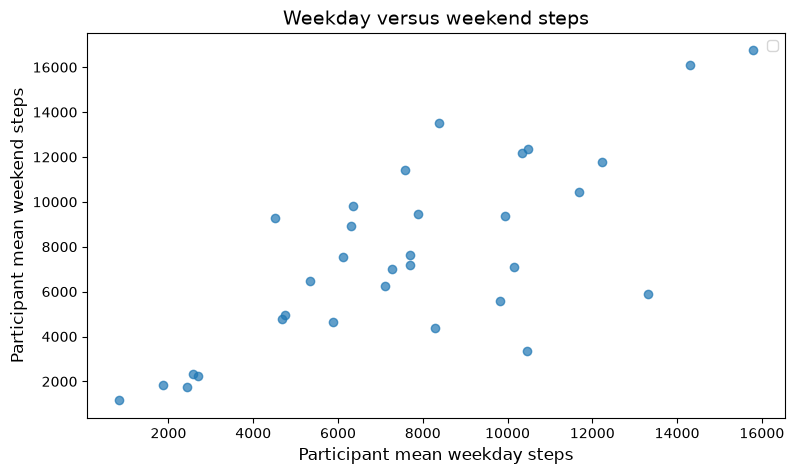

statistic,Weekday,Weekend,WeekendDifference
str,f64,f64,f64
"""count""",32.0,32.0,32.0
"""null_count""",0.0,0.0,0.0
"""mean""",7650.151882,7606.677865,-43.474018
"""std""",3678.444883,4092.856354,2860.537255
"""min""",832.652174,1156.125,-7435.406015
"""25%""",5332.952381,4797.75,-698.478261
"""50%""",7690.043478,7169.75,-25.511905
"""75%""",10161.0,9807.0,1567.761364
"""max""",15792.608696,16751.375,5145.857143


Participants compared: 32
Higher weekend steps: 15


In [49]:
participant_steps = fitbit_data.group_by("Id", "DayType").agg(pl.col("TotalSteps").mean().alias("MeanSteps"))

paired_steps = participant_steps.pivot(on="DayType", index="Id", values="MeanSteps").drop_nulls(["Weekday", "Weekend"])

plt.figure(figsize=(9, 5))
plt.scatter(paired_steps["Weekday"].to_numpy(),paired_steps["Weekend"].to_numpy(),alpha=0.7)

limit = max(paired_steps["Weekday"].max(), paired_steps["Weekend"].max())
plt.xlabel("Participant mean weekday steps", fontsize=12)
plt.ylabel("Participant mean weekend steps", fontsize=12)
plt.title("Weekday versus weekend steps", fontsize=14)
plt.legend()
plt.show()

paired_steps = paired_steps.with_columns(
    (pl.col("Weekend") - pl.col("Weekday")).alias("WeekendDifference")
)

display(paired_steps.select("Weekday", "Weekend", "WeekendDifference").describe())
print("Participants compared:", paired_steps.height)
print("Higher weekend steps:", paired_steps.filter(pl.col("WeekendDifference") > 0).height)

# Relationship 2

In the 32 particpants, 15 were taller than the avg weekend steps. More correlation with higher steps on weekends while other particpants walked more the weekdays (mon - fri.). 7650 on the weekdyas to 7607 on the weekends.

We could look closer into the data on saturday and sunday but there show no major correlation with weekdays and weekend being similar data.